# RehaPiano – štatistická analýza EXACT_FORCE: hypotézy, normy podľa veku, klasifikátor

**Zadanie:** *Pripraviť štatistickú analýzu – stanoviť hypotézy a urobiť testy štatistickej významnosti rozdielu medzi
zdravými a chorými. Urobiť analýzu zmien parametrov u zdravých ľudí s vekom, stanoviť „normálne" hodnoty a rozsahy podľa
dekád. Navrhnúť klasifikátor na oddelenie zdravých a chorých a ablačnú analýzu vplyvu jednotlivých faktorov na výsledok
klasifikácie.*

**Dáta:** test **EXACT_FORCE** – osoba drží všetkými prstami rovnomernú silu, 4 pokusy po 16 s, analyzuje sa úsek 3–15 s.
Ukazovatele každého prsta sú z 3. týždňa (spektrogram, tras 4–15 Hz, pomalé korekcie sily 0–4 Hz). Rovnaký postup ako
pri rytmickom teste (`notebooks/rhythm/statisticka_analyza_rytmus.ipynb`), aby sa testy dali porovnať:
- **Zdraví:** osoby, ktoré v dotazníku (2. týždeň, `data/participant_labels.csv`) neuviedli žiadne ochorenie;
  kontrola so všetkými zdravými je v časti 5. **Pacienti:** všetci.
- Za osobu: pokusy → vyšetrenie → priemer vyšetrení (3. týždeň); u zdravých len krok so 4 pokusmi ako u pacientov.
  Prsty, ktoré netlačia, sa do trasu nepočítajú (ich signál je len šum snímača).

Kód: `src/rehapiano/exact_force/parameters.py` (parametre osoby a faktory), `src/rehapiano/common/stats/group_analysis.py`
(štatistika, klasifikátor, ablácia – rovnaký kód ako pre rytmus), skript `scripts/run_exact_force_analysis.py`
(tabuľky v `outputs/exact_force/analysis/`). Celý projekt sa prepočíta príkazom `python scripts/run_all.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve

# ROOT = repository root (package src/rehapiano, data/, outputs/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import AGE_CATEGORY_LABELS
from rehapiano.exact_force import parameters as ep
from rehapiano.exact_force.config import ANALYSIS_OUTPUT_DIR as OUT

FIG = Path.cwd() / "figures" / "statisticka_analyza_exact_force"; FIG.mkdir(parents=True, exist_ok=True)
T = {path.stem: pd.read_csv(path) for path in sorted(OUT.glob("*.csv"))}
people = T["people"]
people["decade"] = pd.Categorical(people["decade"], AGE_CATEGORY_LABELS, ordered=True)
main = people.loc[people["screened"]].reset_index(drop=True)
healthy = main.loc[main["group"] == "control"]
N_H, N_P = int((main["group"] == "control").sum()), int((main["group"] == "patient").sum())

GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})
SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
GROUPS = ["control", "patient"]
NAME = {"tremor_amplitude": "amplitúda trasu [×10⁻⁵]", "tremor_amplitude_worse_hand": "amplitúda trasu horšej ruky [×10⁻⁵]",
        "movement_amplitude": "pomalé korekcie sily [×10⁻⁵]", "tremor_to_movement": "podiel trasu (4–15 / 0–4 Hz)",
        "tremor_frequency_hz": "frekvencia trasu [Hz]", "tremor_prominence": "rytmickosť trasu (vrchol / medián)",
        "mean_force": "sila [×10⁻³]", "force_balance": "rovnováha síl rúk (slabšia/silnejšia)",
        "tremor_balance": "rovnováha trasu rúk (slabšia/silnejšia)", "finger_spread": "rozdiely medzi prstami (CV)"}
# Amplitudes are ~1e-5 device units: shown multiplied by SCALE; skewed ones on a log axis.
SCALE = {"tremor_amplitude": 1e5, "tremor_amplitude_worse_hand": 1e5, "movement_amplitude": 1e5, "mean_force": 1e3}
LOG_AXIS = {"tremor_amplitude", "tremor_amplitude_worse_hand", "movement_amplitude"}
FEATURE_NAME = {**{f"log_{p}": f"log {NAME[p]}" for p in ep.LOG_PARAMETERS}, **NAME}
scaled = lambda p, v: v * SCALE.get(p, 1)


def fmt(value, digits=2):
    # Slovak decimal comma
    return f"{value:.{digits}f}".replace(".", ",")


def pval(p):
    return "< 0,001" if p < 0.001 else fmt(p, 3)


def short(p):
    return NAME[p].split(" [")[0].split(" (")[0]


def log_axis(ax):
    # log scale with plain numbers (2, 5, 10) instead of 2×10⁰
    ax.set_yscale("log")
    label = lambda v: f"{v:g}".replace(".", ",")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: label(v)))
    ax.yaxis.set_minor_formatter(mticker.FuncFormatter(
        lambda v, _: label(v) if f"{v:.0e}"[0] in "25" else ""))


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150); plt.show()


print(f"zdraví (bez ťažkostí): {N_H}, pacienti: {N_P}, vyšetrení na osobu (medián): {int(main['n_recordings'].median())}")

zdraví (bez ťažkostí): 135, pacienti: 48, vyšetrení na osobu (medián): 1


## Parametre EXACT_FORCE

Z ukazovateľov prstov (3. týždeň) vypočítame pre každú osobu 10 parametrov v 8 skupinách. Skupiny sú **faktory** pre
ablačnú analýzu v časti 4. Ukazovatele prstov sa zhrnú najprv za ruku (medián aktívnych prstov), potom za osobu (priemer
oboch rúk).

| Skupina (faktor) | Parameter | Čo meria | Očakávanie u pacientov |
|---|---|---|---|
| amplitúda trasu | `tremor_amplitude`, `tremor_amplitude_worse_hand` | priemerná amplitúda 4–15 Hz (obe ruky / horšia ruka) | vyššie |
| pomalé korekcie sily | `movement_amplitude` | priemerná amplitúda 0–4 Hz – ako veľmi kolíše držaná sila | vyššie |
| podiel trasu | `tremor_to_movement` | amplitúda 4–15 Hz / amplitúda 0–4 Hz | vyššie |
| frekvencia trasu | `tremor_frequency_hz` | frekvencia najvyššieho vrcholu spektra 4–15 Hz | nižšie (patologický tras 4–6 Hz) |
| rytmickosť trasu | `tremor_prominence` | vrchol / medián spektra 4–15 Hz (≈ 1–2 šum, viac = rytmický tras) | vyššie |
| sila | `mean_force` | priemerná sila prstov oboch rúk | nižšie |
| rovnováha rúk | `force_balance`, `tremor_balance` | slabšia / silnejšia ruka – sila a amplitúda trasu (3. týždeň) | nižšie |
| rozdiely medzi prstami | `finger_spread` | variačný koeficient podielu trasu medzi prstami ruky | vyššie |

Amplitúdy majú veľmi šikmé rozdelenie, preto ich klasifikátor používa v logaritme (testy sú poradové a normy sú
kvantily, tie logaritmus nepotrebujú).

## 1. Hypotézy a testy štatistickej významnosti

Pre každý parameter:
- **H0:** parameter má u zdravých a u pacientov rovnaké rozdelenie.
- **H1:** rozdelenie je rozdielne (smer, ktorý očakávame, je v tabuľke vyššie).

**Testy** (rovnaké ako pri rytmickom teste):
1. **Mann-Whitneyho test**, všetci zdraví vs. všetci pacienti; **AUC** = pravdepodobnosť, že náhodný pacient má vyššiu
   hodnotu ako náhodný zdravý (0,5 = žiadny rozdiel).
2. Ten istý test **len pre osoby ≥ 50 rokov** – zdraví sú mladší, takže rozdiel môže byť vekom.
3. **Lineárny model** parameter = b₀ + b_vek · vek/10 + b_ochorenie · pacient – vplyv ochorenia pri rovnakom veku
   (v smerodajných odchýlkach zdravých); a ten istý model so **silou** navyše – amplitúda trasu rastie so silou,
   ktorou prst tlačí.

P-hodnoty korigujeme **Holmovou metódou** (zvlášť pre každú skupinu testov).

In [2]:
h = T["hypotheses"].set_index("parameter")
table = pd.DataFrame({
    "parameter": [NAME[p] for p in h.index],
    "medián zdraví": [fmt(scaled(p, v), 3) for p, v in h["median_controls"].items()],
    "medián pacienti": [fmt(scaled(p, v), 3) for p, v in h["median_patients"].items()],
    "AUC": h["auc"].round(2).values, "p (Holm)": h["p_holm"].map(pval).values,
    "≥ 50: p (Holm)": h["p_50_holm"].map(pval).values,
    "ochorenie pri rovnakom veku [SD]": h["disease_effect_sd"].round(2).values,
    "p (Holm)​": h["disease_p_holm"].map(pval).values,
    "…aj pri rovnakej sile [SD]": h["disease_effect_adj_sd"].round(2).values,
    "p (Holm)​​": h["disease_adj_p_holm"].map(pval).values,
    "smer podľa H1": np.where(h["as_expected"], "áno", "nie"),
})
display(table)

,parameter,medián zdraví,medián pacienti,AUC,p (Holm),≥ 50: p (Holm),ochorenie pri rovnakom veku [SD],p (Holm)​,…aj pri rovnakej sile [SD],p (Holm)​​,smer podľa H1
0,amplitúda trasu [×10⁻⁵],"0,818","1,371",0.74,"< 0,001","< 0,001",0.79,"0,002",0.62,"0,031",áno
1,amplitúda trasu horšej ruky [×10⁻⁵],"0,931","1,634",0.75,"< 0,001","< 0,001",0.78,"0,006",0.59,"0,042",áno
2,pomalé korekcie sily [×10⁻⁵],"5,492","14,053",0.81,"< 0,001","< 0,001",0.88,"0,004",0.76,"0,002",áno
3,podiel trasu (4–15 / 0–4 Hz),"0,157","0,116",0.30,"< 0,001","0,028",-0.49,"0,018",-0.50,"0,031",nie
4,frekvencia trasu [Hz],"5,267","5,333",0.50,"0,971","0,229",0.06,"1,000",0.10,"0,931",nie
5,rytmickosť trasu (vrchol / medián),"2,853","3,246",0.68,"0,002","0,177",-0.04,"1,000",-0.10,"0,931",áno
6,sila [×10⁻³],"19,914","18,756",0.35,"0,010","< 0,001",-0.71,"0,002",NaN,nan,áno
7,rovnováha síl rúk (slabšia/silnejšia),"0,941","0,915",0.37,"0,036","0,177",-0.64,"0,057",-0.29,"0,500",áno
8,rovnováha trasu rúk (slabšia/silnejšia),"0,825","0,775",0.39,"0,039","0,014",-0.49,"0,095",-0.45,"0,147",áno
9,rozdiely medzi prstami (CV),"0,232","0,303",0.62,"0,039","0,177",0.55,"0,056",0.58,"0,083",áno


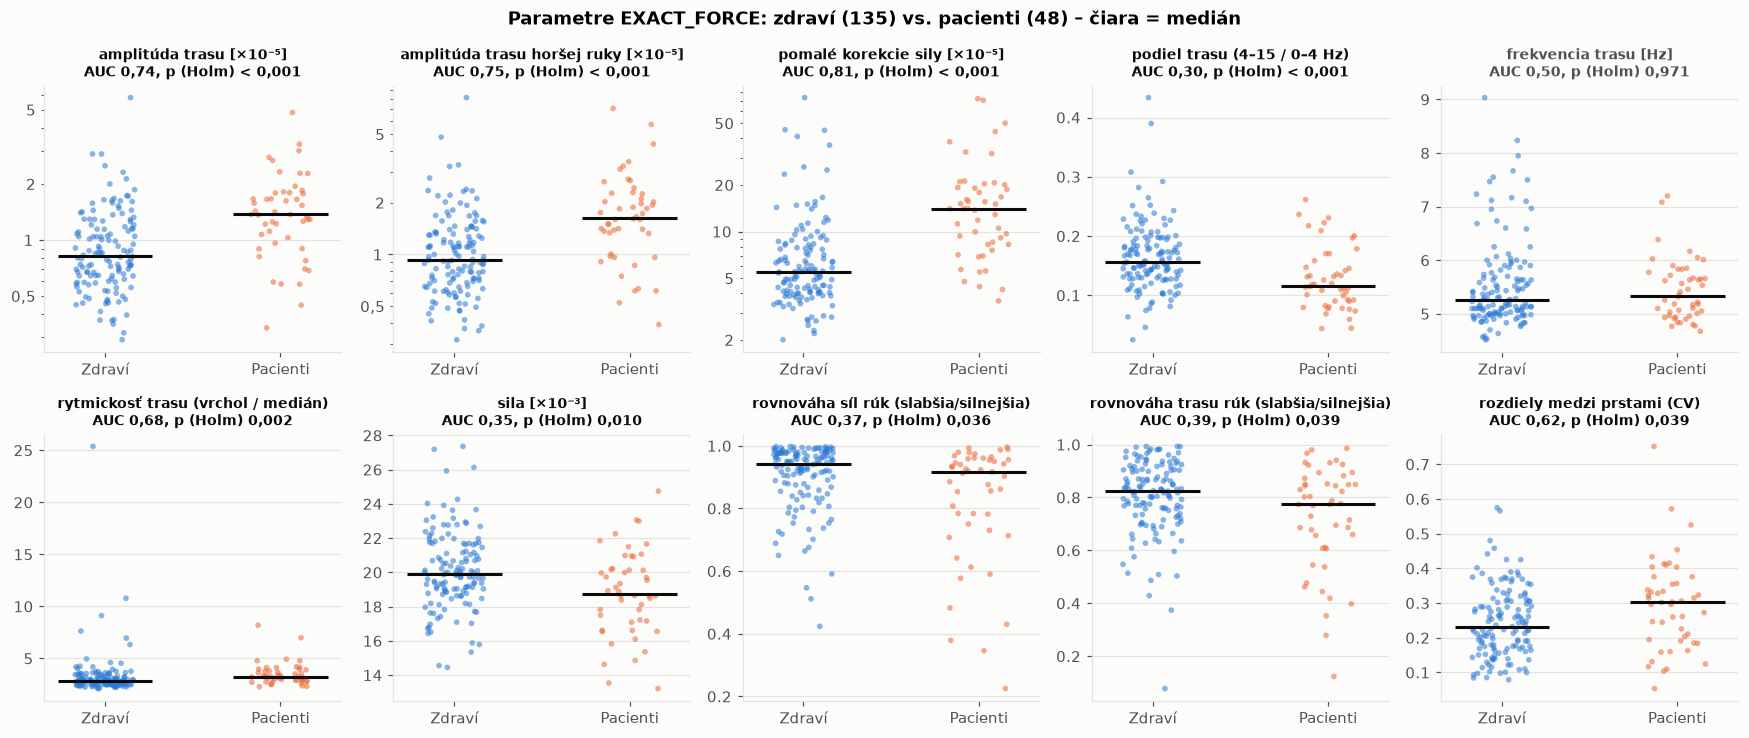

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.8))
rng = np.random.default_rng(0)
for ax, parameter in zip(axes.flat, ep.PARAMETERS):
    for i, group in enumerate(GROUPS):
        v = scaled(parameter, main.loc[main["group"] == group, parameter].dropna())
        ax.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=14, color=GROUP_COLORS[group], alpha=0.55, edgecolor="none")
        ax.hlines(v.median(), i - 0.27, i + 0.27, color=TEXT, lw=2)
    if parameter in LOG_AXIS:
        log_axis(ax)
    p = h.loc[parameter, "p_holm"]
    ax.set_title(f"{NAME[parameter]}\nAUC {fmt(h.loc[parameter, 'auc'])}, p (Holm) {pval(p)}", fontsize=9,
                 color=TEXT if p < 0.05 else MUTED)
    ax.set_xticks([0, 1], [SK_GROUP[g] for g in GROUPS]); ax.grid(axis="x", visible=False)
fig.suptitle(f"Parametre EXACT_FORCE: zdraví ({N_H}) vs. pacienti ({N_P}) – čiara = medián", fontweight="bold")
save(fig, "01_parametre_zdravi_vs_pacienti")

In [4]:
sig = h.loc[h["p_holm"] < 0.05]
sig50 = h.loc[h["p_50_holm"] < 0.05]
sig_age = h.loc[h["disease_p_holm"] < 0.05]
sig_force = h.loc[h["disease_adj_p_holm"] < 0.05]
names = lambda frame: ", ".join(short(p) for p in frame.index) or "žiadny"
opposite = h.loc[(h["p_holm"] < 0.05) & ~h["as_expected"]]
top = h.assign(strength=(h["auc"] - 0.5).abs()).sort_values("strength", ascending=False).head(3)
display(Markdown(f"""
**Záver 1:**
- **H0 zamietame** (Holm p < 0,05, všetci) pre **{len(sig)} z {len(h)} parametrov**: {names(sig)}.
- **Pri porovnaní rovnako starých** (≥ 50 rokov) zostávajú významné: {names(sig50)}; v lineárnom modeli s vekom:
  {names(sig_age)}; ak pridáme aj silu: {names(sig_force)}.
- **Najväčšie rozdiely** (AUC najďalej od 0,5): {", ".join(f"{short(p)} (AUC {fmt(r.auc)})" for p, r in top.iterrows())}.
- Opačný smer, ako sme čakali: {names(opposite)}.
"""))


**Záver 1:**
- **H0 zamietame** (Holm p < 0,05, všetci) pre **9 z 10 parametrov**: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, podiel trasu, rytmickosť trasu, sila, rovnováha síl rúk, rovnováha trasu rúk, rozdiely medzi prstami.
- **Pri porovnaní rovnako starých** (≥ 50 rokov) zostávajú významné: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, podiel trasu, sila, rovnováha trasu rúk; v lineárnom modeli s vekom:
  amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, podiel trasu, sila; ak pridáme aj silu: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, podiel trasu.
- **Najväčšie rozdiely** (AUC najďalej od 0,5): pomalé korekcie sily (AUC 0,81), amplitúda trasu horšej ruky (AUC 0,75), amplitúda trasu (AUC 0,74).
- Opačný smer, ako sme čakali: podiel trasu.


**Interpretácia (dáta z 22. 11. 2026, 135 zdravých a 48 pacientov):** najväčší rozdiel nie je v samotnom trase, ale
v tom, ako pacientom **kolíše celá držaná sila** (pomalé korekcie 0–4 Hz, asi 2,5-krát viac ako u zdravých). Preto je
podiel trasu (4–15 / 0–4 Hz) u pacientov **nižší**, hoci je ich tras silnejší – pomalé kolísanie rastie viac ako tras.
S novými staršími zdravými (9.–13. 11. 2026) zostávajú pomalé korekcie významné aj u osôb ≥ 50 rokov, v modeli s vekom
aj pri rovnakej sile – nie sú teda len dôsledkom veku. Pri rovnakom veku a rovnakej sile zostáva významne vyššia aj
**amplitúda trasu** (aj horšej ruky). Pacienti tlačia pri rovnakom veku **menšou silou**. Frekvencia trasu, rovnováha
rúk a rozdiely medzi prstami sa pri rovnakom veku významne nelíšia.


## 2. Zmeny parametrov s vekom u zdravých a „normálne" hodnoty podľa dekád

**a) Mení sa parameter s vekom?** Iba zdraví: Spearmanova korelácia s vekom a lineárna zmena za 10 rokov.

,parameter,Spearmanovo ρ,p,p (Holm),zmena za 10 rokov,95 % IS,závisí od veku
0,amplitúda trasu [×10⁻⁵],-0.10,"0,237","1,000","-0,0054","[-0,0628; 0,0520]",nie
1,amplitúda trasu horšej ruky [×10⁻⁵],-0.10,"0,228","1,000","0,0075","[-0,0728; 0,0877]",nie
2,pomalé korekcie sily [×10⁻⁵],0.09,"0,301","1,000","0,6983","[-0,0466; 1,4432]",nie
3,podiel trasu (4–15 / 0–4 Hz),-0.27,"0,001","0,012","-0,0065","[-0,0110; -0,0020]",áno
4,frekvencia trasu [Hz],-0.27,"0,002","0,015","-0,1225","[-0,1840; -0,0611]",áno
5,rytmickosť trasu (vrchol / medián),0.36,"< 0,001","< 0,001","0,2366","[0,0595; 0,4136]",áno
6,sila [×10⁻³],0.26,"0,002","0,016","0,2443","[0,0851; 0,4035]",áno
7,rovnováha síl rúk (slabšia/silnejšia),-0.11,"0,191","1,000","-0,0037","[-0,0121; 0,0047]",nie
8,rovnováha trasu rúk (slabšia/silnejšia),0.04,"0,656","1,000","-0,0025","[-0,0135; 0,0085]",nie
9,rozdiely medzi prstami (CV),-0.06,"0,454","1,000","-0,0026","[-0,0106; 0,0054]",nie


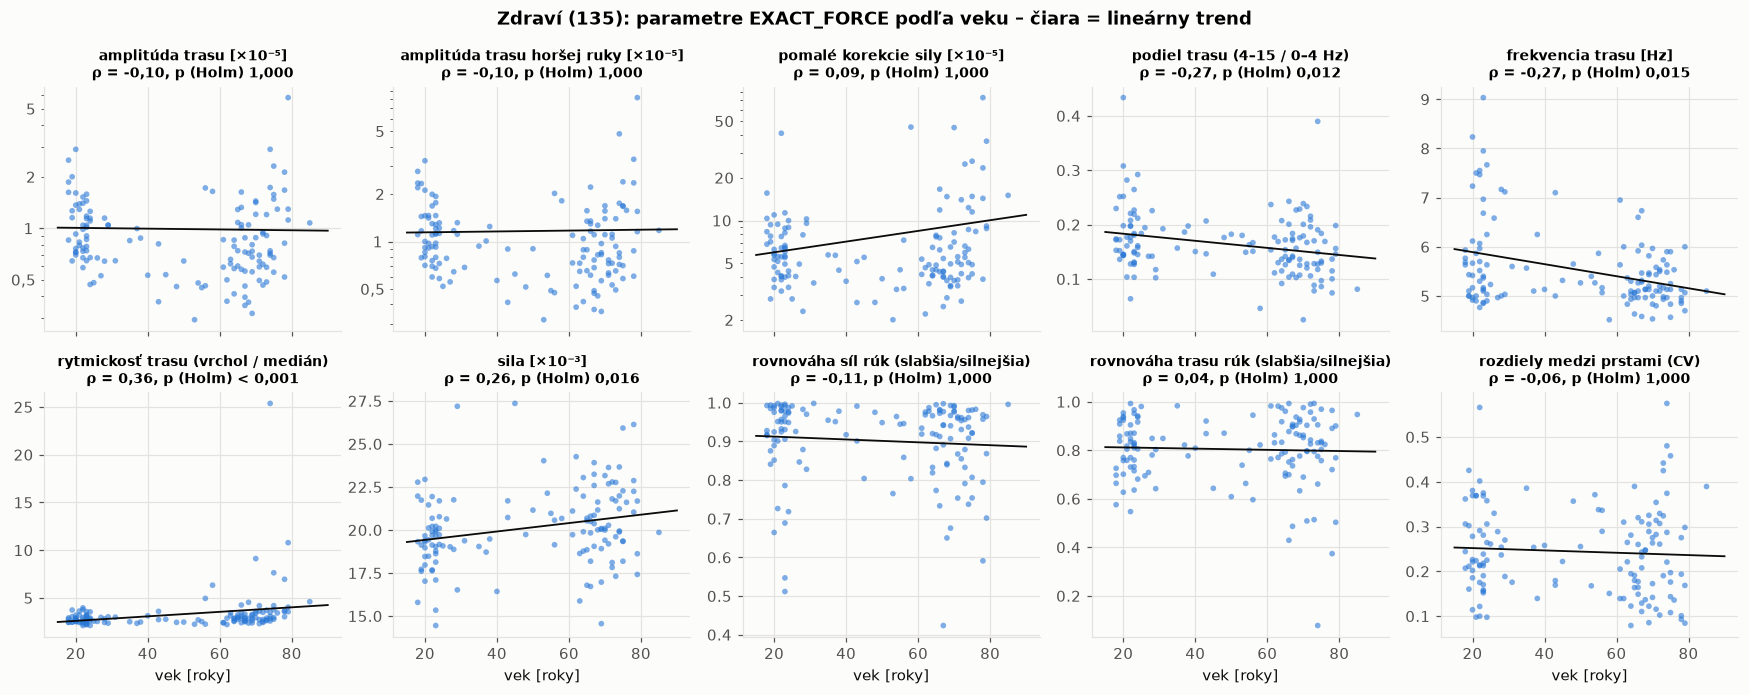

In [5]:
tr = T["age_trends"].set_index("parameter")
display(pd.DataFrame({
    "parameter": [NAME[p] for p in tr.index],
    "Spearmanovo ρ": tr["spearman_rho"].round(2).values, "p": tr["spearman_p"].map(pval).values,
    "p (Holm)": tr["spearman_p_holm"].map(pval).values,
    "zmena za 10 rokov": [fmt(scaled(p, v), 4) for p, v in tr["change_per_10y"].items()],
    "95 % IS": [f"[{fmt(scaled(p, lo), 4)}; {fmt(scaled(p, hi), 4)}]"
                for p, lo, hi in zip(tr.index, tr["change_ci_low"], tr["change_ci_high"])],
    "závisí od veku": np.where(tr["age_dependent"], "áno", "nie")}))

fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), sharex=True)
for ax, parameter in zip(axes.flat, ep.PARAMETERS):
    y = scaled(parameter, healthy[parameter])
    ax.scatter(healthy["age"], y, s=14, color=GROUP_COLORS["control"], alpha=0.6, edgecolor="none")
    fit = np.polyfit(healthy["age"], y, 1)
    x = np.array([15, 90]); ax.plot(x, np.polyval(fit, x), color=TEXT, lw=1.2)
    if parameter in LOG_AXIS:
        log_axis(ax)
    ax.set_title(f"{NAME[parameter]}\nρ = {fmt(tr.loc[parameter, 'spearman_rho'])}, p (Holm) {pval(tr.loc[parameter, 'spearman_p_holm'])}",
                 fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("vek [roky]")
fig.suptitle(f"Zdraví ({N_H}): parametre EXACT_FORCE podľa veku – čiara = lineárny trend", fontweight="bold")
save(fig, "02_zdravi_vek")

In [6]:
dep = tr.loc[tr["age_dependent"]]
nominal = tr.loc[(tr["spearman_p"] < 0.05) & ~tr["age_dependent"]]
describe = lambda frame: ", ".join(f"{short(p)} (ρ = {fmt(r.spearman_rho)})" for p, r in frame.iterrows()) or "nič"
display(Markdown(f"""
Po Holmovej korekcii **{"nezávisí od veku žiadny parameter" if dep.empty else "závisí od veku: " + describe(dep)}**.
Bez korekcie (p < 0,05) sa s vekom mení aj: {describe(nominal)}. Sú to slabé trendy (|ρ| ≤ {fmt(tr["spearman_rho"].abs().max())});
zdraví nad 60 rokov sú však takmer všetci z meraní v meracom centre (9. 9. a 9.–13. 11. 2026) a mladší z iných meraní,
takže trend môže byť aj rozdielom medzi miestami a obdobiami merania.
"""))


Po Holmovej korekcii **závisí od veku: podiel trasu (ρ = -0,27), frekvencia trasu (ρ = -0,27), rytmickosť trasu (ρ = 0,36), sila (ρ = 0,26)**.
Bez korekcie (p < 0,05) sa s vekom mení aj: nič. Sú to slabé trendy (|ρ| ≤ 0,36);
zdraví nad 60 rokov sú však takmer všetci z meraní v meracom centre (9. 9. a 9.–13. 11. 2026) a mladší z iných meraní,
takže trend môže byť aj rozdielom medzi miestami a obdobiami merania.


**b) Normálne hodnoty podľa dekád.** Počet zdravých v dekádach je veľmi nerovnomerný:

In [7]:
counts = healthy["decade"].value_counts(sort=False)
display(counts.rename("zdravých").to_frame().T)

decade,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
zdravých,8,43,4,5,7,33,34,1


In [8]:
reliable = [d for d in AGE_CATEGORY_LABELS if counts.get(d, 0) >= 20]
display(Markdown(f"""
Spoľahlivý empirický rozsah (2,5. – 97,5. percentil) potrebuje aspoň ~20 osôb – to majú len dekády
**{", ".join(reliable)}** rokov; v ostatných je zdravých málo.
Preto normu počítame **zo všetkých zdravých naraz** (rovnako ako pri rytmickom teste):
- parameter **bez vplyvu veku** → rovnaký rozsah pre všetky dekády (2,5. – 97,5. percentil všetkých zdravých);
- parameter **s vplyvom veku** (po Holmovej korekcii) → kvantilová regresia na vek (medián a hranice sa menia lineárne
  s vekom), hodnota v strede dekády.

Hodnota pacienta **mimo rozsahu** = mimo rozsahu 95 % zdravých jeho veku.
"""))



Spoľahlivý empirický rozsah (2,5. – 97,5. percentil) potrebuje aspoň ~20 osôb – to majú len dekády
**20–29, 60–69, 70–79** rokov; v ostatných je zdravých málo.
Preto normu počítame **zo všetkých zdravých naraz** (rovnako ako pri rytmickom teste):
- parameter **bez vplyvu veku** → rovnaký rozsah pre všetky dekády (2,5. – 97,5. percentil všetkých zdravých);
- parameter **s vplyvom veku** (po Holmovej korekcii) → kvantilová regresia na vek (medián a hranice sa menia lineárne
  s vekom), hodnota v strede dekády.

Hodnota pacienta **mimo rozsahu** = mimo rozsahu 95 % zdravých jeho veku.


In [9]:
model_norms = T["norms_by_age_model"]
emp = T["decade_norms"]
rows = []
for parameter in ep.PARAMETERS:
    m = model_norms.loc[model_norms["parameter"] == parameter].set_index("decade")
    row = {"parameter": NAME[parameter], "metóda": m["method"].iloc[0]}
    for decade in AGE_CATEGORY_LABELS:
        q = {k: scaled(parameter, m.loc[decade, k]) for k in ("q2.5", "q50", "q97.5")}
        row[decade] = f"{fmt(q['q50'], 3)} [{fmt(q['q2.5'], 3)}–{fmt(q['q97.5'], 3)}]"
    rows.append(row)
print(f"Normálne hodnoty: medián [2,5. – 97,5. percentil] pre každú dekádu (zo všetkých {N_H} zdravých):")
display(pd.DataFrame(rows).set_index("parameter"))

e = emp.copy()
sc = e["parameter"].map(lambda p: SCALE.get(p, 1))
e["empiricky"] = np.where(e["reliable"], (e["median"] * sc).map(lambda v: fmt(v, 3)) + " [" + (e["p2_5"] * sc).map(lambda v: fmt(v, 3))
                          + "–" + (e["p97_5"] * sc).map(lambda v: fmt(v, 3)) + "]",
                          np.where(e["n"] > 0, (e["median"] * sc).map(lambda v: fmt(v, 3)) + " (n=" + e["n"].astype(str) + ", málo)", "–"))
print("Kontrola – empiricky v každej dekáde zvlášť (rozsah len pri n ≥ 20, inak iba medián):")
display(e.pivot(index="parameter", columns="decade", values="empiricky").reindex(index=ep.PARAMETERS, columns=AGE_CATEGORY_LABELS)
        .rename(index=NAME))

Normálne hodnoty: medián [2,5. – 97,5. percentil] pre každú dekádu (zo všetkých 135 zdravých):


,metóda,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
parameter,,,,,,,,,
amplitúda trasu [×10⁻⁵],spoločná norma (bez vplyvu veku),"0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]","0,818 [0,370–2,435]"
amplitúda trasu horšej ruky [×10⁻⁵],spoločná norma (bez vplyvu veku),"0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]","0,931 [0,393–3,087]"
pomalé korekcie sily [×10⁻⁵],spoločná norma (bez vplyvu veku),"5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]","5,492 [2,541–39,374]"
podiel trasu (4–15 / 0–4 Hz),kvantilová regresia na vek,"0,175 [0,107–0,315]","0,169 [0,102–0,301]","0,162 [0,096–0,287]","0,156 [0,091–0,273]","0,150 [0,086–0,259]","0,144 [0,081–0,246]","0,138 [0,076–0,232]","0,132 [0,071–0,218]"
frekvencia trasu [Hz],kvantilová regresia na vek,"5,567 [4,898–8,411]","5,495 [4,838–8,056]","5,423 [4,777–7,701]","5,350 [4,717–7,346]","5,278 [4,656–6,991]","5,206 [4,595–6,636]","5,133 [4,535–6,280]","5,061 [4,474–5,925]"
rytmickosť trasu (vrchol / medián),kvantilová regresia na vek,"2,561 [2,075–3,117]","2,633 [2,118–4,315]","2,705 [2,161–5,513]","2,778 [2,205–6,711]","2,850 [2,248–7,909]","2,923 [2,291–9,107]","2,995 [2,334–10,305]","3,067 [2,377–11,503]"
sila [×10⁻³],kvantilová regresia na vek,"19,247 [15,084–22,668]","19,492 [15,404–23,211]","19,737 [15,725–23,753]","19,982 [16,045–24,296]","20,227 [16,366–24,838]","20,472 [16,686–25,381]","20,717 [17,006–25,923]","20,962 [17,327–26,466]"
rovnováha síl rúk (slabšia/silnejšia),spoločná norma (bez vplyvu veku),"0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]","0,941 [0,612–0,996]"
rovnováha trasu rúk (slabšia/silnejšia),spoločná norma (bez vplyvu veku),"0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]","0,825 [0,492–0,988]"


Kontrola – empiricky v každej dekáde zvlášť (rozsah len pri n ≥ 20, inak iba medián):


decade,10–19,20–29,30–39,40–49,50–59,60–69,70–79,80–89
parameter,,,,,,,,
amplitúda trasu [×10⁻⁵],"1,444 (n=8, málo)","0,925 [0,483–1,607]","0,862 (n=4, málo)","0,531 (n=5, málo)","0,479 (n=7, málo)","0,679 [0,347–1,385]","0,916 [0,482–3,408]","1,075 (n=1, málo)"
amplitúda trasu horšej ruky [×10⁻⁵],"1,817 (n=8, málo)","1,101 [0,556–2,109]","0,971 (n=4, málo)","0,566 (n=5, málo)","0,610 (n=7, málo)","0,795 [0,369–1,696]","1,079 [0,524–5,401]","1,176 (n=1, málo)"
pomalé korekcie sily [×10⁻⁵],"8,056 (n=8, málo)","5,592 [2,828–11,308]","5,084 (n=4, málo)","3,741 (n=5, málo)","3,896 (n=7, málo)","4,497 [2,426–15,108]","6,836 [3,342–49,984]","15,034 (n=1, málo)"
podiel trasu (4–15 / 0–4 Hz),"0,172 (n=8, málo)","0,170 [0,102–0,307]","0,189 (n=4, málo)","0,150 (n=5, málo)","0,163 (n=7, málo)","0,142 [0,100–0,238]","0,141 [0,066–0,265]","0,081 (n=1, málo)"
frekvencia trasu [Hz],"5,533 (n=8, málo)","5,517 [4,851–8,219]","5,583 (n=4, málo)","5,317 (n=5, málo)","5,267 (n=7, málo)","5,200 [4,623–6,777]","5,133 [4,561–5,973]","5,100 (n=1, málo)"
rytmickosť trasu (vrchol / medián),"2,616 (n=8, málo)","2,760 [2,115–3,758]","2,488 (n=4, málo)","2,763 (n=5, málo)","2,522 (n=7, málo)","2,866 [2,334–4,312]","3,452 [2,408–13,337]","4,606 (n=1, málo)"
sila [×10⁻³],"19,223 (n=8, málo)","19,395 [15,399–22,889]","19,208 (n=4, málo)","20,725 (n=5, málo)","20,967 (n=7, málo)","20,086 [15,613–23,981]","21,135 [17,398–25,960]","19,858 (n=1, málo)"
rovnováha síl rúk (slabšia/silnejšia),"0,923 (n=8, málo)","0,950 [0,553–0,996]","0,966 (n=4, málo)","0,917 (n=5, málo)","0,944 (n=7, málo)","0,934 [0,605–0,995]","0,934 [0,682–0,990]","0,996 (n=1, málo)"
rovnováha trasu rúk (slabšia/silnejšia),"0,782 (n=8, málo)","0,817 [0,627–0,980]","0,835 (n=4, málo)","0,869 (n=5, málo)","0,738 (n=7, málo)","0,862 [0,475–0,985]","0,828 [0,322–0,991]","0,947 (n=1, málo)"


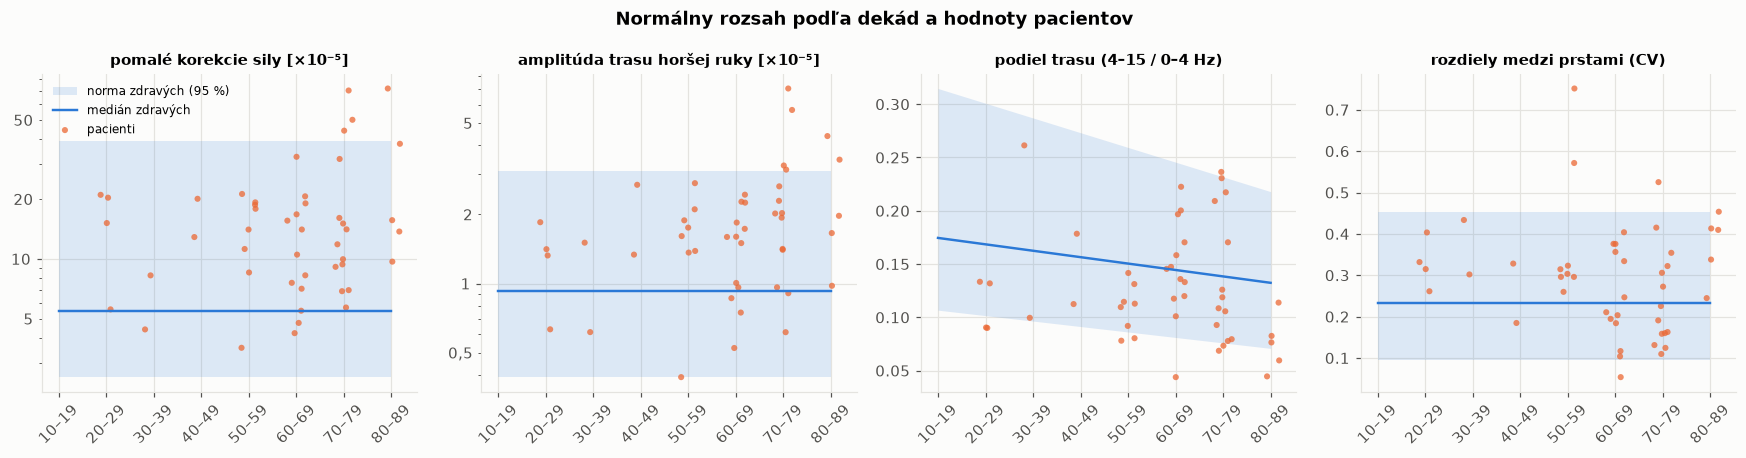

Koľko pacientov je mimo normálneho rozsahu svojej dekády:


,pod normou,nad normou,pacientov
parameter,,,
amplitúda trasu [×10⁻⁵],1,5,48
amplitúda trasu horšej ruky [×10⁻⁵],1,6,48
pomalé korekcie sily [×10⁻⁵],0,4,48
podiel trasu (4–15 / 0–4 Hz),9,1,48
frekvencia trasu [Hz],1,1,48
rytmickosť trasu (vrchol / medián),0,0,48
sila [×10⁻³],9,1,48
rovnováha síl rúk (slabšia/silnejšia),7,1,48
rovnováha trasu rúk (slabšia/silnejšia),8,0,48


In [10]:
KEY = ["movement_amplitude", "tremor_amplitude_worse_hand", "tremor_to_movement", "finger_spread"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
x = np.arange(len(AGE_CATEGORY_LABELS))
pts = main.loc[main["group"] == "patient"]
pos = pts["decade"].cat.codes.to_numpy() + np.random.default_rng(1).uniform(-0.2, 0.2, len(pts))
for ax, parameter in zip(axes, KEY):
    m = model_norms.loc[model_norms["parameter"] == parameter].set_index("decade").reindex(AGE_CATEGORY_LABELS)
    ax.fill_between(x, scaled(parameter, m["q2.5"]), scaled(parameter, m["q97.5"]), color=GROUP_COLORS["control"],
                    alpha=0.15, lw=0, label="norma zdravých (95 %)")
    ax.plot(x, scaled(parameter, m["q50"]), color=GROUP_COLORS["control"], lw=1.6, label="medián zdravých")
    ax.scatter(pos, scaled(parameter, pts[parameter]), s=16, color=GROUP_COLORS["patient"], alpha=0.75, edgecolor="none",
               label="pacienti")
    if parameter in LOG_AXIS:
        log_axis(ax)
    ax.set_xticks(x, AGE_CATEGORY_LABELS, rotation=45); ax.set_title(NAME[parameter], fontsize=9.5)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Normálny rozsah podľa dekád a hodnoty pacientov", fontweight="bold")
save(fig, "03_normy_podla_dekad")

outside = T["outside_norms"].set_index("parameter")
print("Koľko pacientov je mimo normálneho rozsahu svojej dekády:")
display(outside.rename(index=NAME, columns={"below": "pod normou", "above": "nad normou", "n_patients": "pacientov"}))

## 3. Klasifikátor: zdravý vs. pacient

**Modely** (rovnaké ako pri rytmickom teste): **logistická regresia** (hlavný model – jednoduchý a dá sa vysvetliť;
parametre sú štandardizované, triedy vyvážené) a **náhodný les** (300 stromov).

**Hodnotenie:** **opakovaná 5-násobná krížová validácia** (20 opakovaní) – model sa učí na 4/5 osôb a hodnotí na zvyšnej
1/5, ktorú nevidel. Uvádzame priemer a 95 % rozsah cez opakovania: **AUC**, **citlivosť** (rozpoznaní pacienti)
a **špecificitu** (rozpoznaní zdraví) pri prahu 0,5.

**Pozor na vek:** pacienti sú starší, preto porovnávame aj klasifikátor **len podľa veku** a klasifikátor
**len na osobách ≥ 50 rokov**.

In [11]:
clf = T["classifier"]
mainclf = clf.loc[clf["main"]]
MAIN_SET = mainclf["set"].iloc[0]
show = lambda frame: pd.DataFrame({
    "množina": frame["set"], "príznaky": frame["features"], "model": frame["model"], "osôb": frame["n_people"],
    "AUC": frame["auc"].map(fmt) + " [" + frame["auc_low"].map(fmt) + "–" + frame["auc_high"].map(fmt) + "]",
    "citlivosť": frame["sensitivity"].map(fmt), "špecificita": frame["specificity"].map(fmt),
    "vyvážená presnosť": frame["balanced_accuracy"].map(fmt)}).reset_index(drop=True)
display(show(mainclf))
perm = T["permutation_test"].iloc[0]
print(f"Permutačný test (logistická regresia, parametre EF): AUC {fmt(perm['auc'])}, s náhodne pomiešanými skupinami "
      f"priemer {fmt(perm['null_mean'])} (97,5 % {fmt(perm['null_p97_5'])}), p = {pval(perm['p'])}")

,množina,príznaky,model,osôb,AUC,citlivosť,špecificita,vyvážená presnosť
0,135 zdravých + 48 pacientov,parametre EF,logistická regresia,183,"0,77 [0,75–0,80]","0,66","0,78","0,72"
1,135 zdravých + 48 pacientov,parametre EF + vek,logistická regresia,183,"0,82 [0,80–0,84]","0,74","0,79","0,77"
2,135 zdravých + 48 pacientov,len vek,logistická regresia,183,"0,64 [0,63–0,65]","0,73","0,49","0,61"
3,135 zdravých + 48 pacientov,parametre EF,náhodný les,183,"0,77 [0,75–0,80]","0,65","0,77","0,71"
4,135 zdravých + 48 pacientov,parametre EF + vek,náhodný les,183,"0,81 [0,78–0,83]","0,70","0,80","0,75"
5,135 zdravých + 48 pacientov,len vek,náhodný les,183,"0,66 [0,63–0,68]","0,59","0,67","0,63"
6,"135 zdravých + 48 pacientov, len ≥ 50 rokov",parametre EF,logistická regresia,115,"0,84 [0,80–0,86]","0,72","0,83","0,78"
7,"135 zdravých + 48 pacientov, len ≥ 50 rokov",parametre EF,náhodný les,115,"0,78 [0,76–0,80]","0,71","0,77","0,74"


Permutačný test (logistická regresia, parametre EF): AUC 0,78, s náhodne pomiešanými skupinami priemer 0,50 (97,5 % 0,60), p = 0,005


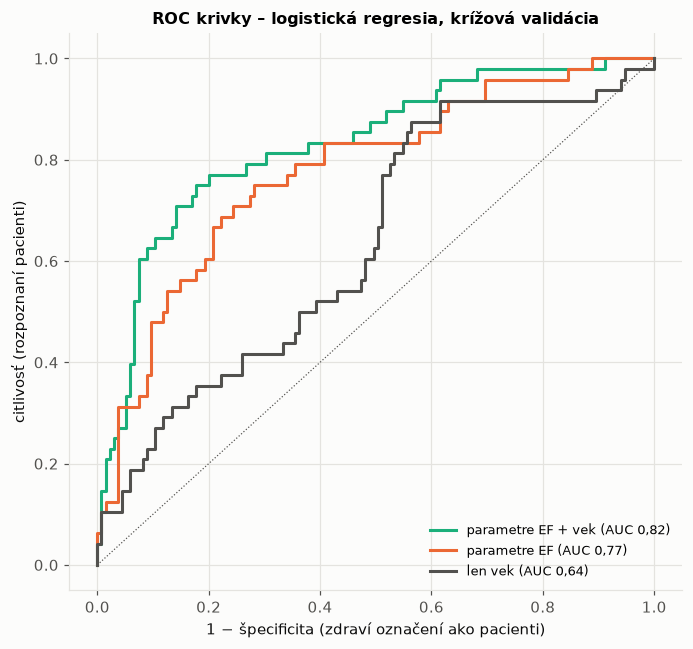

In [12]:
oof = T["classifier_oof"]
fig, ax = plt.subplots(figsize=(6.4, 6))
styles = [("parametre EF + vek", "#1baf7a"), ("parametre EF", GROUP_COLORS["patient"]), ("len vek", MUTED)]
for label, color in styles:
    fpr, tpr, _ = roc_curve(oof["patient"], oof[f"logistická regresia | {label}"])
    auc = mainclf.loc[(mainclf["model"] == "logistická regresia") & (mainclf["features"] == label), "auc"].iloc[0]
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {fmt(auc)})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("1 − špecificita (zdraví označení ako pacienti)"); ax.set_ylabel("citlivosť (rozpoznaní pacienti)")
ax.set_title("ROC krivky – logistická regresia, krížová validácia"); ax.legend(loc="lower right", fontsize=8.5)
save(fig, "04_roc")

In [13]:
get = lambda feat, model="logistická regresia", s=MAIN_SET: clf.loc[
    (clf["set"] == s) & (clf["features"] == feat) & (clf["model"] == model)].iloc[0]
p_lr, pa_lr, a_lr = get("parametre EF"), get("parametre EF + vek"), get("len vek")
o_lr, o_rf = get("parametre EF", s=f"{MAIN_SET}, len ≥ 50 rokov"), get("parametre EF", "náhodný les", s=f"{MAIN_SET}, len ≥ 50 rokov")
rf = get("parametre EF", "náhodný les")
n50 = main.loc[main["age"] >= 50].groupby("group").size()
display(Markdown(f"""
**Záver 3:**
- Logistická regresia z 10 parametrov EXACT_FORCE oddelí pacientov so **AUC {fmt(p_lr["auc"])}** (citlivosť
  {fmt(p_lr["sensitivity"])}, špecificita {fmt(p_lr["specificity"])}); výrazne lepšie ako náhoda (permutačný test p
  {pval(perm["p"])}). Náhodný les dosahuje AUC {fmt(rf["auc"])}.
- **Samotný vek** dosahuje AUC {fmt(a_lr["auc"])} – pacienti sú starší. Vek a parametre EF spolu dávajú AUC
  {fmt(pa_lr["auc"])}, čiže **EXACT_FORCE pridáva informáciu navyše k veku**.
- **Rovnako starí (≥ 50 rokov, {n50.get("control", 0)} zdravých a {n50.get("patient", 0)} pacientov):** parametre EF stále
  oddeľujú skupiny s AUC {fmt(o_lr["auc"])} [{fmt(o_lr["auc_low"])}–{fmt(o_lr["auc_high"])}] (náhodný les
  {fmt(o_rf["auc"])}) – rozdiel teda nie je len vekom.{" Výsledok je však menej istý (málo starších zdravých)." if n50.get("control", 0) < 30 else ""}
"""))


**Záver 3:**
- Logistická regresia z 10 parametrov EXACT_FORCE oddelí pacientov so **AUC 0,77** (citlivosť
  0,66, špecificita 0,78); výrazne lepšie ako náhoda (permutačný test p
  0,005). Náhodný les dosahuje AUC 0,77.
- **Samotný vek** dosahuje AUC 0,64 – pacienti sú starší. Vek a parametre EF spolu dávajú AUC
  0,82, čiže **EXACT_FORCE pridáva informáciu navyše k veku**.
- **Rovnako starí (≥ 50 rokov, 75 zdravých a 40 pacientov):** parametre EF stále
  oddeľujú skupiny s AUC 0,84 [0,80–0,86] (náhodný les
  0,78) – rozdiel teda nie je len vekom.


## 4. Ablačná analýza – vplyv jednotlivých faktorov

Pre každú skupinu parametrov (faktor) zopakujeme krížovú validáciu logistickej regresie:
- **bez faktora** – model dostane všetky ostatné parametre; pokles AUC = čo stratíme, keď faktor vynecháme,
- **iba faktor** – model dostane len tento faktor; AUC = koľko dokáže faktor sám.

Robíme to dvakrát: (A) iba parametre EF, (B) parametre EF + vek ako ďalší faktor.

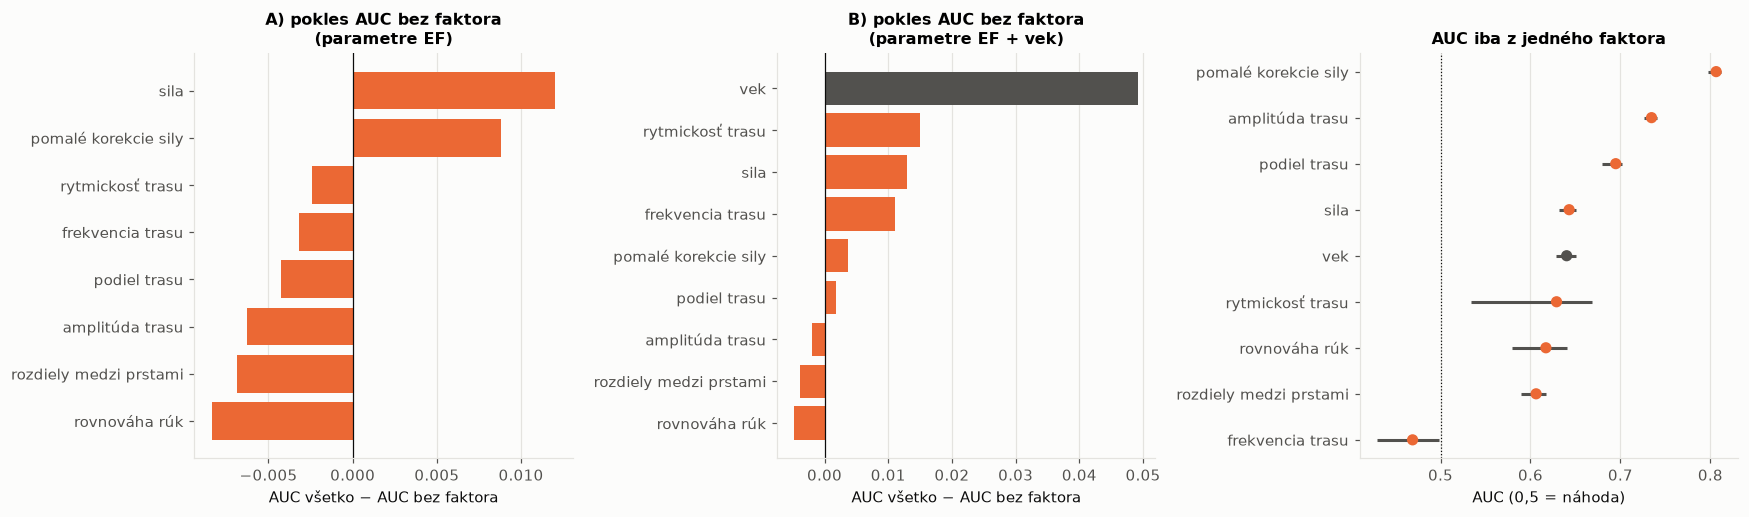

,parametre,AUC bez faktora,pokles AUC,AUC iba faktor
faktor,,,,
sila,log_mean_force,0.763,0.012,0.643
pomalé korekcie sily,log_movement_amplitude,0.766,0.009,0.806
rytmickosť trasu,tremor_prominence,0.777,-0.002,0.629
frekvencia trasu,tremor_frequency_hz,0.778,-0.003,0.469
podiel trasu,tremor_to_movement,0.779,-0.004,0.695
amplitúda trasu,"log_tremor_amplitude, log_tremor_amplitude_wor...",0.781,-0.006,0.735
rozdiely medzi prstami,finger_spread,0.781,-0.007,0.606
rovnováha rúk,"force_balance, tremor_balance",0.783,-0.008,0.617


Koeficienty logistickej regresie (štandardizované parametre, všetky osoby; + = vyššia hodnota → skôr pacient):


,coefficient,odds_ratio_per_sd
feature,,
log pomalé korekcie sily [×10⁻⁵],0.95,2.59
rytmickosť trasu (vrchol / medián),-0.70,0.50
podiel trasu (4–15 / 0–4 Hz),-0.61,0.55
log sila [×10⁻³],-0.53,0.59
frekvencia trasu [Hz],0.40,1.50
log amplitúda trasu horšej ruky [×10⁻⁵],0.21,1.23
rovnováha síl rúk (slabšia/silnejšia),0.20,1.22
rovnováha trasu rúk (slabšia/silnejšia),-0.19,0.83
log amplitúda trasu [×10⁻⁵],0.14,1.16


In [14]:
abl = T["ablation_parameters"]; abl_age = T["ablation_with_age"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, frame, title in [(axes[0], abl, "A) pokles AUC bez faktora\n(parametre EF)"),
                         (axes[1], abl_age, "B) pokles AUC bez faktora\n(parametre EF + vek)")]:
    frame = frame.sort_values("auc_drop")
    colors = [MUTED if g == "vek" else GROUP_COLORS["patient"] for g in frame["group"]]
    ax.barh(frame["group"], frame["auc_drop"], color=colors)
    ax.axvline(0, color=TEXT, lw=0.8); ax.set_title(title); ax.set_xlabel("AUC všetko − AUC bez faktora")
    ax.grid(axis="y", visible=False)
alone = abl_age.sort_values("auc_alone")
axes[2].hlines(range(len(alone)), alone["auc_alone_low"], alone["auc_alone_high"], color=MUTED, lw=2)
axes[2].scatter(alone["auc_alone"], range(len(alone)), color=[MUTED if g == "vek" else GROUP_COLORS["patient"] for g in alone["group"]],
                s=40, zorder=3)
axes[2].set_yticks(range(len(alone)), alone["group"]); axes[2].axvline(0.5, color=TEXT, lw=0.8, ls=":")
axes[2].set_title("AUC iba z jedného faktora"); axes[2].set_xlabel("AUC (0,5 = náhoda)"); axes[2].grid(axis="y", visible=False)
save(fig, "05_ablacia")
display(pd.DataFrame({"faktor": abl["group"], "parametre": abl["features"], "AUC bez faktora": abl["auc_without"].round(3),
                      "pokles AUC": abl["auc_drop"].round(3), "AUC iba faktor": abl["auc_alone"].round(3)}).set_index("faktor"))
coef = T["classifier_coefficients"]
print("Koeficienty logistickej regresie (štandardizované parametre, všetky osoby; + = vyššia hodnota → skôr pacient):")
display(coef.assign(feature=coef["feature"].map(FEATURE_NAME)).round(2).set_index("feature"))

In [15]:
top_alone = abl.sort_values("auc_alone", ascending=False).head(3)
weak_alone = abl.loc[abl["auc_alone"] < 0.65]
age_row = abl_age.set_index("group").loc["vek"]
top_drop = abl.iloc[0]
display(Markdown(f"""
**Záver 4:**
- **Samy osebe** oddeľujú skupiny najlepšie: {", ".join(f"{r.group} (AUC {fmt(r.auc_alone)})" for r in top_alone.itertuples())}.
  Slabé samy osebe (AUC < 0,65): {", ".join(weak_alone["group"]) or "žiadny"}.
- **Po vynechaní** jedného faktora AUC klesne najviac pri faktore **{top_drop["group"]}** (o {fmt(top_drop["auc_drop"], 3)}).
  Ostatné poklesy sú malé, lebo parametre sa **navzájom zastupujú** (amplitúda trasu, pomalé korekcie a podiel trasu
  sú z toho istého spektra).
- Ak je v modeli aj **vek**, jeho vynechanie zníži AUC o {fmt(age_row["auc_drop"], 3)} – vek je v týchto dátach silne
  zviazaný so skupinou.
"""))


**Záver 4:**
- **Samy osebe** oddeľujú skupiny najlepšie: pomalé korekcie sily (AUC 0,81), amplitúda trasu (AUC 0,73), podiel trasu (AUC 0,69).
  Slabé samy osebe (AUC < 0,65): sila, rytmickosť trasu, frekvencia trasu, rozdiely medzi prstami, rovnováha rúk.
- **Po vynechaní** jedného faktora AUC klesne najviac pri faktore **sila** (o 0,012).
  Ostatné poklesy sú malé, lebo parametre sa **navzájom zastupujú** (amplitúda trasu, pomalé korekcie a podiel trasu
  sú z toho istého spektra).
- Ak je v modeli aj **vek**, jeho vynechanie zníži AUC o 0,049 – vek je v týchto dátach silne
  zviazaný so skupinou.


## 5. Kontrola: všetci zdraví

Hlavná analýza používa len zdravých bez ťažkostí podľa dotazníka. Kontrola s **všetkými** zdravými:

In [16]:
checks = clf.loc[~clf["main"] & (clf["model"] == "logistická regresia")]
display(show(checks))
h_all = T["hypotheses_all_healthy"].set_index("parameter")
display(pd.DataFrame({f"hlavná analýza ({N_H} zdravých)": h["p_holm"].map(pval),
                      f"všetci zdraví ({int(h_all.n_controls.max())})": h_all["p_holm"].map(pval),
                      "AUC hlavná": h["auc"].round(2), "AUC všetci zdraví": h_all["auc"].round(2)})
        .rename(index=NAME).rename_axis("Mann-Whitney p (Holm) a AUC"))

,množina,príznaky,model,osôb,AUC,citlivosť,špecificita,vyvážená presnosť
0,167 zdravých + 48 pacientov,parametre EF,logistická regresia,215,"0,76 [0,74–0,78]","0,65","0,76","0,71"
1,167 zdravých + 48 pacientov,parametre EF + vek,logistická regresia,215,"0,80 [0,78–0,82]","0,71","0,78","0,74"
2,167 zdravých + 48 pacientov,len vek,logistická regresia,215,"0,61 [0,60–0,62]","0,70","0,44","0,57"
3,"167 zdravých + 48 pacientov, len ≥ 50 rokov",parametre EF,logistická regresia,140,"0,83 [0,79–0,85]","0,72","0,81","0,76"


,hlavná analýza (135 zdravých),všetci zdraví (167),AUC hlavná,AUC všetci zdraví
Mann-Whitney p (Holm) a AUC,,,,
amplitúda trasu [×10⁻⁵],"< 0,001","< 0,001",0.74,0.73
amplitúda trasu horšej ruky [×10⁻⁵],"< 0,001","< 0,001",0.75,0.74
pomalé korekcie sily [×10⁻⁵],"< 0,001","< 0,001",0.81,0.79
podiel trasu (4–15 / 0–4 Hz),"< 0,001","< 0,001",0.30,0.31
frekvencia trasu [Hz],"0,971","0,712",0.50,0.52
rytmickosť trasu (vrchol / medián),"0,002","0,013",0.68,0.64
sila [×10⁻³],"0,010","0,004",0.35,0.34
rovnováha síl rúk (slabšia/silnejšia),"0,036","0,043",0.37,0.38
rovnováha trasu rúk (slabšia/silnejšia),"0,039","0,070",0.39,0.40


In [17]:
display(Markdown(f"""
## Zhrnutie

1. **Hypotézy:** pre {len(sig)} z {len(h)} parametrov EXACT_FORCE zamietame H0 – zdraví a pacienti sa líšia.
   Pri rovnakom veku zostávajú významné: {names(sig_age)}.
2. **Vek u zdravých:** po korekcii na viacnásobné testovanie {"sa s vekom nemení žiadny parameter" if dep.empty else "závisí od veku: " + ", ".join(short(p) for p in dep.index)};
   **normálne hodnoty** podľa dekád sú v časti 2b (pre parametre bez vplyvu veku rovnaké pre všetky dekády).
   Empiricky v každej dekáde zvlášť sa dajú určiť len pre {", ".join(reliable)} rokov.
3. **Klasifikátor:** logistická regresia z parametrov EF – AUC {fmt(p_lr["auc"])}, s vekom {fmt(pa_lr["auc"])};
   samotný vek {fmt(a_lr["auc"])}; len ≥ 50 rokov {fmt(o_lr["auc"])}.
4. **Ablácia:** najviac sám prispieva faktor **{top_alone.iloc[0]["group"]}**; parametre sa navzájom zastupujú.

Porovnanie a spojenie s rytmickým testom: `notebooks/combined/klasifikator_oba_testy.ipynb`.

**Obmedzenia:** zdraví a pacienti hrali inú verziu hry (iné `step_id`) a pacienti sú starší – klasifikátor preto
čiastočne môže rozoznávať vek alebo verziu hry; zdraví nad 60 rokov sú takmer všetci z meracieho centra (iné miesto
merania ako mladší zdraví); poradie prstov (malíček … palec) nie je overené; klasifikátor nie je overený na nezávislých
dátach.
"""))


## Zhrnutie

1. **Hypotézy:** pre 9 z 10 parametrov EXACT_FORCE zamietame H0 – zdraví a pacienti sa líšia.
   Pri rovnakom veku zostávajú významné: amplitúda trasu, amplitúda trasu horšej ruky, pomalé korekcie sily, podiel trasu, sila.
2. **Vek u zdravých:** po korekcii na viacnásobné testovanie závisí od veku: podiel trasu, frekvencia trasu, rytmickosť trasu, sila;
   **normálne hodnoty** podľa dekád sú v časti 2b (pre parametre bez vplyvu veku rovnaké pre všetky dekády).
   Empiricky v každej dekáde zvlášť sa dajú určiť len pre 20–29, 60–69, 70–79 rokov.
3. **Klasifikátor:** logistická regresia z parametrov EF – AUC 0,77, s vekom 0,82;
   samotný vek 0,64; len ≥ 50 rokov 0,84.
4. **Ablácia:** najviac sám prispieva faktor **pomalé korekcie sily**; parametre sa navzájom zastupujú.

Porovnanie a spojenie s rytmickým testom: `notebooks/combined/klasifikator_oba_testy.ipynb`.

**Obmedzenia:** zdraví a pacienti hrali inú verziu hry (iné `step_id`) a pacienti sú starší – klasifikátor preto
čiastočne môže rozoznávať vek alebo verziu hry; zdraví nad 60 rokov sú takmer všetci z meracieho centra (iné miesto
merania ako mladší zdraví); poradie prstov (malíček … palec) nie je overené; klasifikátor nie je overený na nezávislých
dátach.
